In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scn.data import (get_constituents, download_prices, clean_prices,
                      drop_duplicate_share_classes, log_returns)
from scn.network import minimum_spanning_tree, same_sector_share, shuffled_sector_share
from scn.plots import mst_figure

cons = get_constituents()
prices = download_prices(cons["ticker"].tolist(), "2015-01-01", "2025-12-31")
returns = log_returns(drop_duplicate_share_classes(clean_prices(prices)))
sectors = cons.set_index("ticker")["sector"].loc[returns.columns]
names = cons.set_index("ticker")["name"].loc[returns.columns]
C = returns.corr()
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
print(len(C), "stocks")

455 stocks


In [2]:
T = minimum_spanning_tree(C)
print("is a tree:", nx.is_tree(T))
print(T.number_of_nodes(), "stocks,", T.number_of_edges(), "links (should be N - 1)")

is a tree: True
455 stocks, 454 links (should be N - 1)


In [3]:
edges = pd.DataFrame([(u, v, d["corr"]) for u, v, d in T.edges(data=True)], columns=["a", "b", "corr"])
edges["name_a"] = names.loc[edges["a"]].values
edges["name_b"] = names.loc[edges["b"]].values
edges["same_sector"] = sectors.loc[edges["a"]].values == sectors.loc[edges["b"]].values
edges.sort_values("corr", ascending=False).head(12)

,a,b,corr,name_a,name_b,same_sector
452,UDR,VMRK,0.915751,"UDR, Inc.",Vivmark Residential,True
281,FRT,REG,0.914190,Federal Realty Investment Trust,Regency Centers,True
276,FITB,RF,0.908517,Fifth Third Bancorp,Regions Financial Corporation,True
396,MET,PRU,0.905479,MetLife,Prudential Financial,True
154,CFG,FITB,0.897983,Citizens Financial Group,Fifth Third Bancorp,True
251,ESS,UDR,0.897834,Essex Property Trust,"UDR, Inc.",True
47,AMAT,LRCX,0.897325,Applied Materials,Lam Research,True
153,CFG,KEY,0.895815,Citizens Financial Group,KeyCorp,True
378,MA,V,0.894447,Mastercard,Visa Inc.,True
208,DHI,LEN,0.894265,D. R. Horton,Lennar,True


In [4]:
deg = pd.Series(dict(T.degree())).sort_values(ascending=False)
hubs = deg.head(12).to_frame("links")
hubs["name"] = names.loc[hubs.index]
hubs["sector"] = sectors.loc[hubs.index]
print("leaves (only one link):", (deg == 1).sum(), f"= {(deg == 1).mean():.0%} of stocks")
hubs

leaves (only one link): 258 = 57% of stocks


,links,name,sector
PH,15,Parker Hannifin,Industrials
PRU,15,Prudential Financial,Financials
MCO,14,Moody's Corporation,Financials
ITW,12,Illinois Tool Works,Industrials
AMP,10,Ameriprise Financial,Financials
PEP,9,PepsiCo,Consumer Staples
TEL,9,TE Connectivity,Information Technology
SYK,8,Stryker Corporation,Health Care
DUK,7,Duke Energy,Utilities
MSFT,7,Microsoft,Information Technology


In [5]:
observed = same_sector_share(T, sectors.to_dict())
null = shuffled_sector_share(T, sectors, n_shuffles=1000)
z = (observed - null.mean()) / null.std()
print(f"same-sector links: {observed:.1%}")
print(f"expected by chance: {null.mean():.1%} ± {null.std():.1%}")
print(f"z-score: {z:.0f} standard deviations above chance")

same-sector links: 80.8%
expected by chance: 11.1% ± 1.6%
z-score: 45 standard deviations above chance


In [6]:
rows = []
for s in sorted(sectors.unique()):
    links = [(u, v) for u, v in T.edges() if sectors[u] == s or sectors[v] == s]
    inside = sum(sectors[u] == sectors[v] for u, v in links)
    rows.append({"sector": s, "links touching": len(links), "share within sector": inside / len(links)})
pd.DataFrame(rows).sort_values("share within sector", ascending=False)

,sector,links touching,share within sector
3,Energy,21,0.904762
10,Utilities,30,0.900000
5,Health Care,57,0.859649
9,Real Estate,31,0.774194
2,Consumer Staples,32,0.750000
7,Information Technology,74,0.729730
6,Industrials,91,0.615385
4,Financials,115,0.608696
8,Materials,24,0.541667
1,Consumer Discretionary,50,0.540000


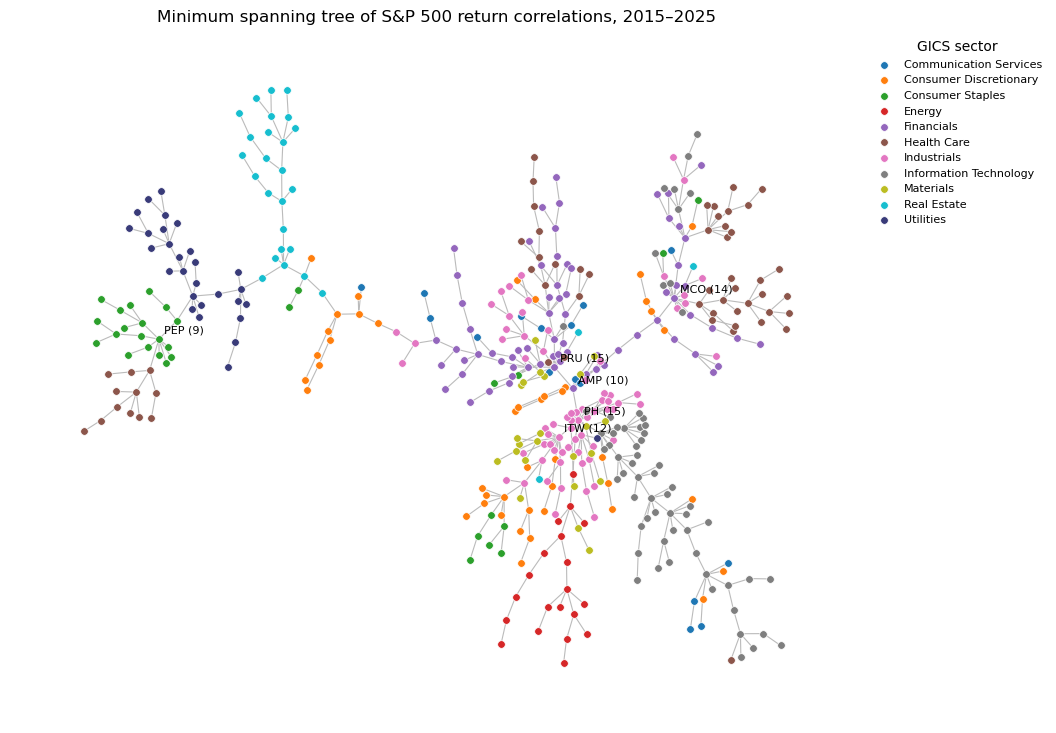

In [9]:
fig = mst_figure(T, sectors, "Minimum spanning tree of S&P 500 return correlations, 2015–2025", label_top = 6)
fig.savefig(FIG / "mst.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
pd.DataFrame({"name": names.loc[list(T.neighbors("MCO"))],
              "sector": sectors.loc[list(T.neighbors("MCO"))]})

,name,sector
CPRT,Copart,Industrials
EFX,Equifax,Industrials
FDS,FactSet,Financials
BLK,BlackRock,Financials
BR,Broadridge Financial Solutions,Industrials
CTAS,Cintas,Industrials
FICO,Fair Isaac,Information Technology
GEN,Gen Digital,Information Technology
IQV,IQVIA,Health Care
NDAQ,"Nasdaq, Inc.",Financials
